<a href="https://colab.research.google.com/github/fabianmoore/MineriaDatos/blob/main/Actividad2_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q --upgrade kagglehub statsmodels

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from google.colab import userdata
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
# El token se lee de Colab Secrets (nunca escrito en el notebook)
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ruta_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Carpeta:", ruta_bc)
print(os.listdir(ruta_bc))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Carpeta: /kaggle/input/breast-cancer-wisconsin-data
['data.csv']


In [4]:
df_bc = pd.read_csv(os.path.join(ruta_bc, "data.csv"))
print(df_bc.shape)
df_bc.info()
print(df_bc.isnull().sum()[df_bc.isnull().sum() > 0])
df_bc.head()

(569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
cols_descartadas = ["id", "diagnosis", "Unnamed: 32"]
df = df_bc.drop(columns=cols_descartadas)

print(df.shape)
print("Nulos totales:", df.isnull().sum().sum())
df[["radius_mean", "perimeter_mean", "area_mean"]].describe()

(569, 30)
Nulos totales: 0


,radius_mean,perimeter_mean,area_mean
count,569.000000,569.000000,569.000000
mean,14.127292,91.969033,654.889104
std,3.524049,24.298981,351.914129
min,6.981000,43.790000,143.500000
25%,11.700000,75.170000,420.300000
50%,13.370000,86.240000,551.100000
75%,15.780000,104.100000,782.700000
max,28.110000,188.500000,2501.000000


id: Identificador del paciente, no mide nada del
núcleo celular.


diagnosis: Etiqueta M/B (texto), no es una medición numérica.


Unnamed: 32: 0 valores no nulos, columna vacía del CSV.


Resultado: 569 filas × 30 columnas numéricas y 0 nulos.

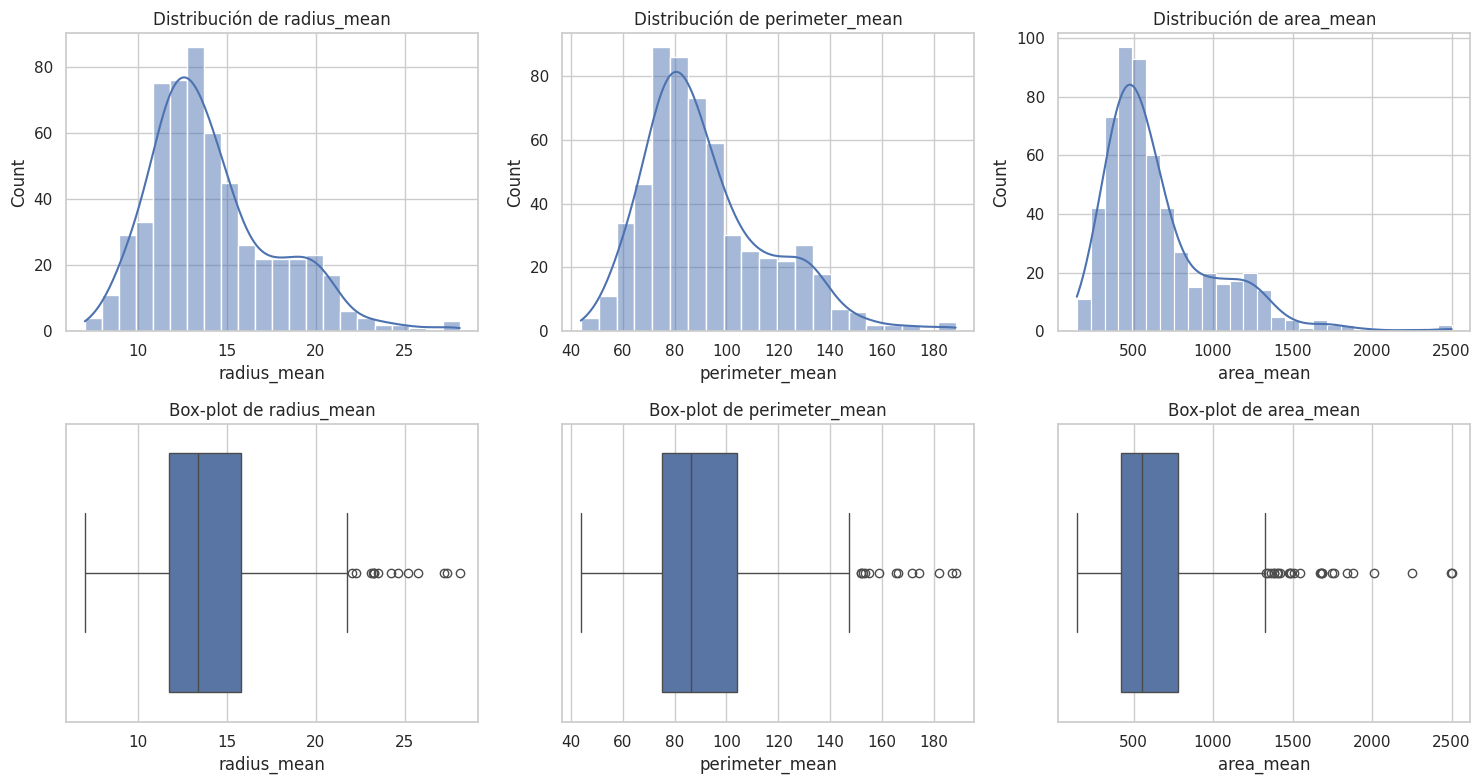

In [6]:
vars_modelo = ["radius_mean", "perimeter_mean", "area_mean"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for i, v in enumerate(vars_modelo):
    sns.histplot(df[v], kde=True, ax=ejes[0, i])
    ejes[0, i].set_title(f"Distribución de {v}")
    sns.boxplot(x=df[v], ax=ejes[1, i])
    ejes[1, i].set_title(f"Box-plot de {v}")
plt.tight_layout()
plt.show()

En las tres variables la media es mayor que la mediana (radio 14,13 vs 13,37; perímetro 91,97 vs 86,24; área 654,9 vs 551,1). Eso indica asimetría a la derecha, y los histogramas lo muestran.

Los box-plots tienen puntos atípicos solo en el lado alto.

area_mean es la más extrema: llega a 2501 con una mediana de 551.

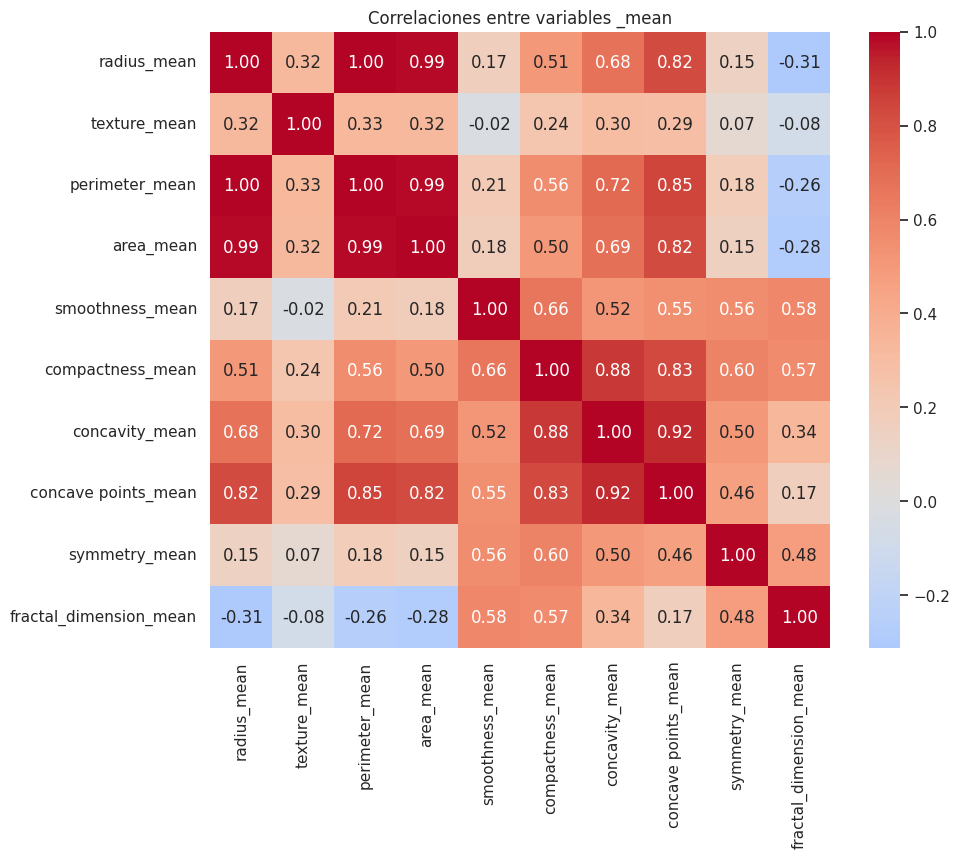

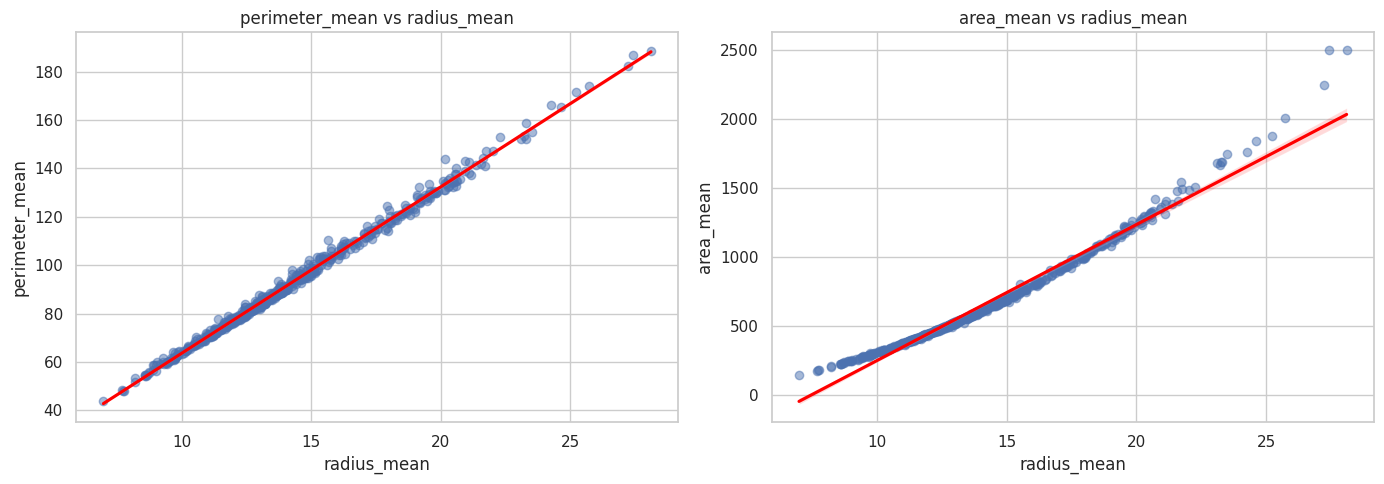

In [7]:
# Correlaciones (solo las variables "_mean" para que el gráfico sea legible)
cols_mean = [c for c in df.columns if c.endswith("_mean")]
plt.figure(figsize=(10, 8))
sns.heatmap(df[cols_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones entre variables _mean")
plt.show()

# Nube de puntos con línea de regresión de los dos modelos
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x="radius_mean", y="perimeter_mean", ax=ejes[0],
            line_kws={"color": "red"}, scatter_kws={"alpha": 0.5})
ejes[0].set_title("perimeter_mean vs radius_mean")
sns.regplot(data=df, x="radius_mean", y="area_mean", ax=ejes[1],
            line_kws={"color": "red"}, scatter_kws={"alpha": 0.5})
ejes[1].set_title("area_mean vs radius_mean")
plt.tight_layout()
plt.show()

radius_mean con perimeter_mean: 1,00; con area_mean: 0,99.

Otras variables relacionadas con el radio: concave points_mean (0,82) y concavity_mean (0,68). texture_mean (0,32) y fractal_dimension_mean (−0,31) tienen una relación débil.

EDA:

Distribución y atípicos: Las variables de tamaño (radius_mean, perimeter_mean, area_mean) tienen asimetría a la derecha (media > mediana) y valores atípicos solo en el extremo superior. Se conservaron por tratarse de mediciones reales, aunque pueden influir en la pendiente.

Selección de variables: radius_mean correlaciona 1,00 con perimeter_mean y 0,99 con area_mean, lo que respalda su uso como predictor de ambas. Variables como texture_mean (0,32) y fractal_dimension_mean (−0,31) tienen baja correlación con el radio y no se consideraron.

Linealidad: [aquí tu observación de las nubes de puntos]. Como una correlación alta no garantiza una relación lineal, se verificará con el análisis de residuos antes de confirmar el modelo.

In [8]:
# Predictor (X debe ser 2D) y objetivos
X = df[["radius_mean"]]
y_per = df["perimeter_mean"]
y_area = df["area_mean"]

# Partición 80/20 con semilla fija (misma partición para ambos modelos)
X_train, X_test, yper_train, yper_test, yarea_train, yarea_test = train_test_split(
    X, y_per, y_area, test_size=0.2, random_state=RANDOM_STATE
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

# Modelo 1: perimeter_mean ~ radius_mean
modelo_per = LinearRegression().fit(X_train, yper_train)

# Modelo 2: area_mean ~ radius_mean
modelo_area = LinearRegression().fit(X_train, yarea_train)

for nombre, m in [("perimeter_mean", modelo_per), ("area_mean", modelo_area)]:
    print(f"\nModelo {nombre} ~ radius_mean")
    print(f"  Pendiente : {m.coef_[0]:.4f}")
    print(f"  Intercepto: {m.intercept_:.4f}")

Entrenamiento: (455, 1) | Prueba: (114, 1)

Modelo perimeter_mean ~ radius_mean
  Pendiente : 6.8640
  Intercepto: -5.0208

Modelo area_mean ~ radius_mean
  Pendiente : 99.0408
  Intercepto: -743.8449


In [9]:
def metricas(modelo, X_te, y_te):
    pred = modelo.predict(X_te)
    return {
        "R²": r2_score(y_te, pred),
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
    }

resultados = pd.DataFrame({
    "perimeter_mean": metricas(modelo_per, X_test, yper_test),
    "area_mean": metricas(modelo_area, X_test, yarea_test),
}).T
resultados.round(4)

,R²,MAE,RMSE
perimeter_mean,0.9957,1.0424,1.5834
area_mean,0.9812,34.9748,46.5776


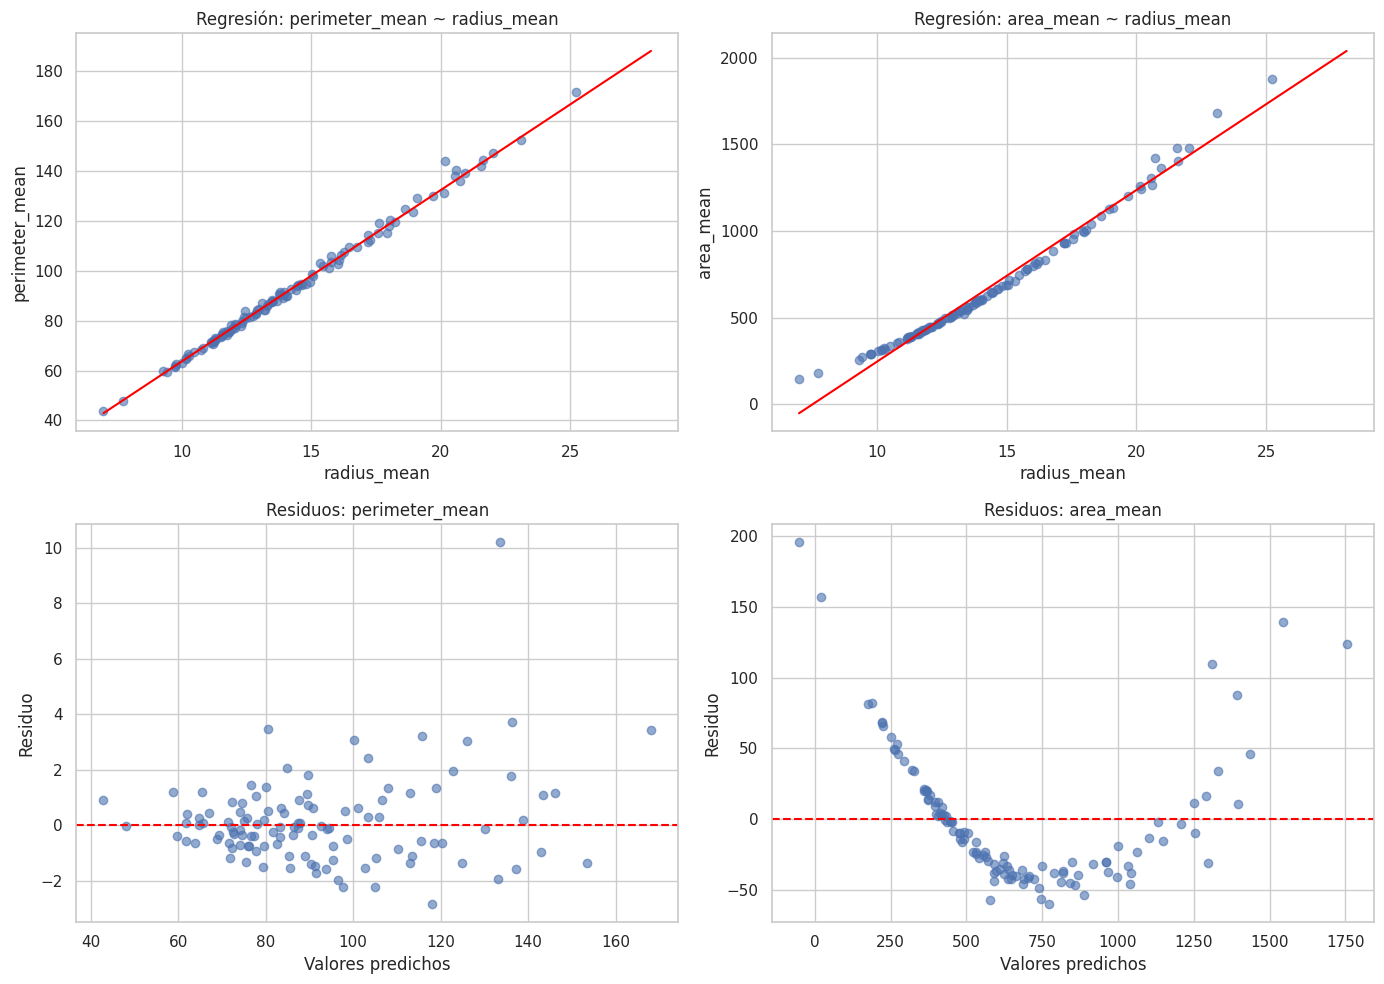

In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

for col, (nombre, modelo, y_te) in enumerate([
    ("perimeter_mean", modelo_per, yper_test),
    ("area_mean", modelo_area, yarea_test),
]):
    pred = modelo.predict(X_test)
    residuos = y_te - pred

    # Fila 0: nube de puntos (prueba) con la línea de regresión
    ejes[0, col].scatter(X_test["radius_mean"], y_te, alpha=0.6)
    xs = np.linspace(X["radius_mean"].min(), X["radius_mean"].max(), 100)
    ejes[0, col].plot(xs, modelo.predict(pd.DataFrame({"radius_mean": xs})), color="red")
    ejes[0, col].set_title(f"Regresión: {nombre} ~ radius_mean")
    ejes[0, col].set_xlabel("radius_mean")
    ejes[0, col].set_ylabel(nombre)

    # Fila 1: residuos vs. valores predichos
    ejes[1, col].scatter(pred, residuos, alpha=0.6)
    ejes[1, col].axhline(0, color="red", linestyle="--")
    ejes[1, col].set_title(f"Residuos: {nombre}")
    ejes[1, col].set_xlabel("Valores predichos")
    ejes[1, col].set_ylabel("Residuo")

plt.tight_layout()
plt.show()

Interpretación de la pendiente y el intercepto:

Modelo del perímetro (perimeter_mean ~ radius_mean):

*   Pendiente (6,86): Por cada unidad
que aumenta el radio, el perímetro aumenta en promedio unas 6,86 unidades. Es coherente con la teoría ($2\pi \cdot r \approx 6,28 \cdot r$); la ligera variación puede deberse a que los núcleos celulares no son círculos perfectos.
*   Intercepto (–5,02): Es el valor predicho para un radio de 0; carece de interpretación física y funciona solo como ajuste matemático.

Modelo del área (area_mean ~ radius_mean)
*  Pendiente (99,04):Indica que el área aumenta en promedio unas 99 unidades por cada unidad de radio. Al ser el área una función cuadrática, este valor es solo un promedio de un efecto no constante, lo que explica por qué la recta no se ajusta a la curvatura.
*   Intercepto (–743,84): Al ser negativo, carece de sentido físico (un radio de 0 no puede tener área negativa), reflejando el mal ajuste de forzar un modelo lineal en una relación curva.

¿Un R² alto es suficiente para concluir que una recta es el modelo adecuado?

No. Aunque ambos modelos presentan un R² alto en el conjunto de prueba (0,9957 para el perímetro y 0,9812 para el área), solo el primero cumple con el supuesto de linealidad.

Modelo del perímetro: los residuos se distribuyen al azar alrededor de 0 con dispersión homogénea (con un único caso aislado en +10), lo que indica que la recta describe adecuadamente la relación.
Modelo del área: los residuos revelan un patrón sistemático en forma de U, evidenciando un error no aleatorio. Además, la nube de puntos muestra una curvatura evidente y, al ajustar una recta a una relación curva, el modelo predice áreas negativas para radios pequeños (intercepto de -743,84), lo que no tiene sentido físico.

El origen del problema es geométrico: el perímetro crece linealmente respecto al radio, mientras que el área lo hace de forma cuadrática. Por ello, una recta ajusta bien el perímetro, pero es incapaz de seguir la curvatura del área, a pesar de mantener un R² elevado.

En conclusión: el R² solo indica cuánta variabilidad explica el modelo, mas no si su estructura es la correcta. Para verificar esto último, el análisis de residuos es indispensable.

In [11]:
ruta_fifa = kagglehub.dataset_download("javagarm/fifa-19-complete-player-dataset")
print("Carpeta:", ruta_fifa)
for raiz, carpetas, archivos in os.walk(ruta_fifa):
    for a in archivos:
        print(os.path.join(raiz, a))

100%|██████████| 2.16M/2.16M [00:00<00:00, 109MB/s]

Extracting files...
Carpeta: /root/.cache/kagglehub/datasets/javagarm/fifa-19-complete-player-dataset/versions/1
/root/.cache/kagglehub/datasets/javagarm/fifa-19-complete-player-dataset/versions/1/kl.csv


In [12]:
ruta_csv = os.path.join(ruta_fifa, "kl.csv")

try:
    df_fifa = pd.read_csv(ruta_csv, encoding="cp1252")
except UnicodeDecodeError:
    df_fifa = pd.read_csv(ruta_csv, encoding="latin-1")

print(df_fifa.shape)
df_fifa.info()
print(df_fifa.isnull().sum().sort_values(ascending=False).head(15))
df_fifa.head()

(18207, 89)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 89 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                18207 non-null  int64  
 1   ID                        18207 non-null  int64  
 2   Name                      18207 non-null  object 
 3   Age                       18206 non-null  float64
 4   Photo                     18207 non-null  object 
 5   Nationality               18207 non-null  object 
 6   Flag                      18207 non-null  object 
 7   Overall                   18206 non-null  float64
 8   Potential                 18207 non-null  int64  
 9   Club                      17966 non-null  object 
 10  Club Logo                 18207 non-null  object 
 11  Value                     18207 non-null  object 
 12  Wage                      18207 non-null  object 
 13  Special                   18207 non-null  int64  

,Unnamed: 0,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,0,158023,L. Messi,31.0,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94.0,94,FC Barcelona,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,1,20801,Cristiano Ronaldo,33.0,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94.0,94,Juventus,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,2,190871,Neymar Jr,26.0,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92.0,93,Paris Saint-Germain,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,3,193080,De Gea,27.0,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91.0,93,Manchester United,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,4,192985,K. De Bruyne,27.0,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91.0,92,Manchester City,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [13]:
cols_no_utiles = ["Unnamed: 0", "ID", "Photo", "Flag", "Club Logo"]
df_f = df_fifa.drop(columns=cols_no_utiles)

print("Nulos en Overall:", df_f["Overall"].isnull().sum())
df_f = df_f.dropna(subset=["Overall"])
print(df_f.shape)
df_f["Overall"].describe()

Nulos en Overall: 1
(18206, 84)


,Overall
count,18206.000000
mean,66.237449
std,6.907059
min,46.000000
25%,62.000000
50%,66.000000
75%,71.000000
max,94.000000


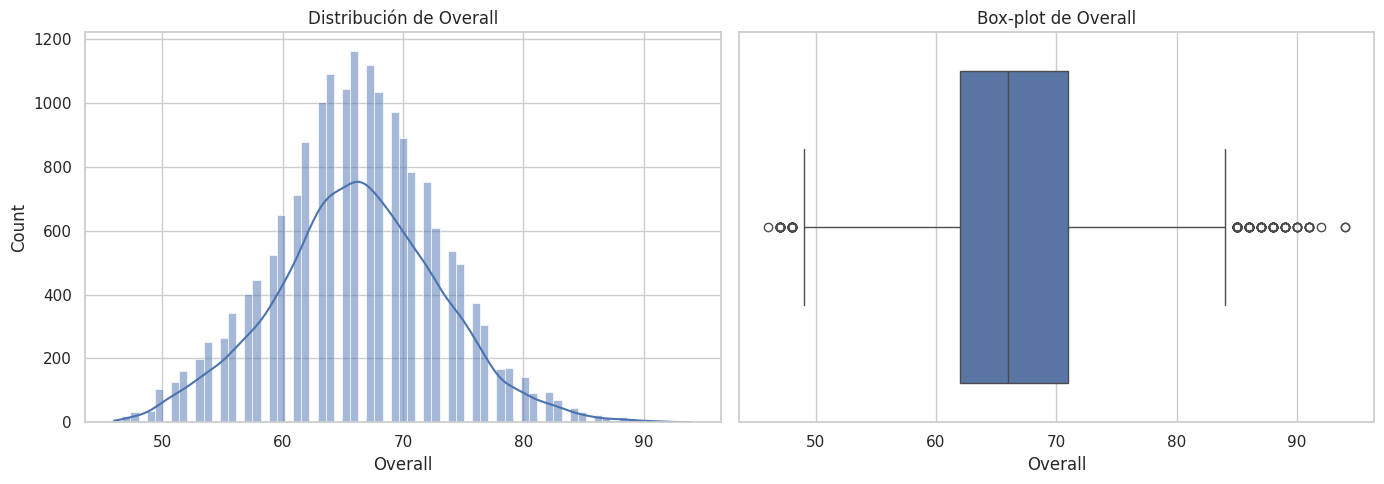

Reactions                   0.850
Composure                   0.728
Potential                   0.661
Special                     0.607
ShortPassing                0.503
International Reputation    0.499
Vision                      0.499
LongPassing                 0.484
BallControl                 0.461
Age                         0.452
ShotPower                   0.442
LongShots                   0.421
Curve                       0.420
Skill Moves                 0.415
FKAccuracy                  0.397
Aggression                  0.396
Crossing                    0.395
Volleys                     0.392
Dribbling                   0.373
Stamina                     0.366
Positioning                 0.357
Strength                    0.349
Penalties                   0.342
HeadingAccuracy             0.341
Finishing                   0.333
Interceptions               0.322
Marking                     0.287
Agility                     0.265
Jumping                     0.264
StandingTackle

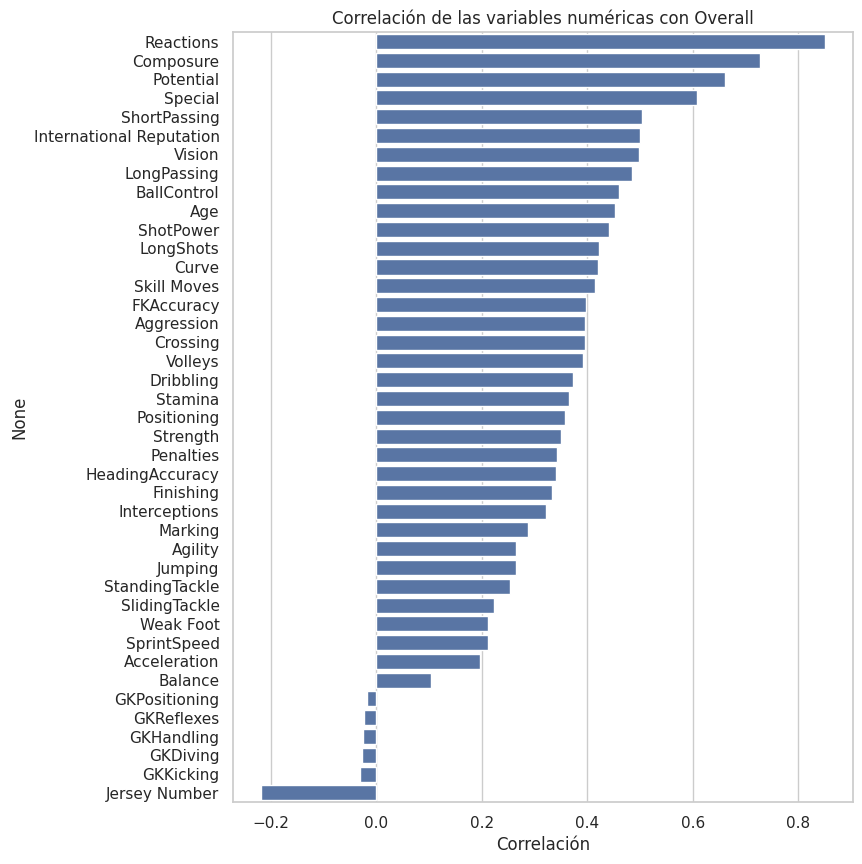

In [14]:
# Distribución y box-plot de la variable objetivo
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_f["Overall"], kde=True, ax=ejes[0])
ejes[0].set_title("Distribución de Overall")
sns.boxplot(x=df_f["Overall"], ax=ejes[1])
ejes[1].set_title("Box-plot de Overall")
plt.tight_layout()
plt.show()

# Correlación de cada variable numérica con Overall
num = df_f.select_dtypes(include="number")
corr_overall = num.corr()["Overall"].drop("Overall").sort_values(ascending=False)
print(corr_overall.round(3))

plt.figure(figsize=(8, 10))
sns.barplot(x=corr_overall.values, y=corr_overall.index)
plt.title("Correlación de las variables numéricas con Overall")
plt.xlabel("Correlación")
plt.show()

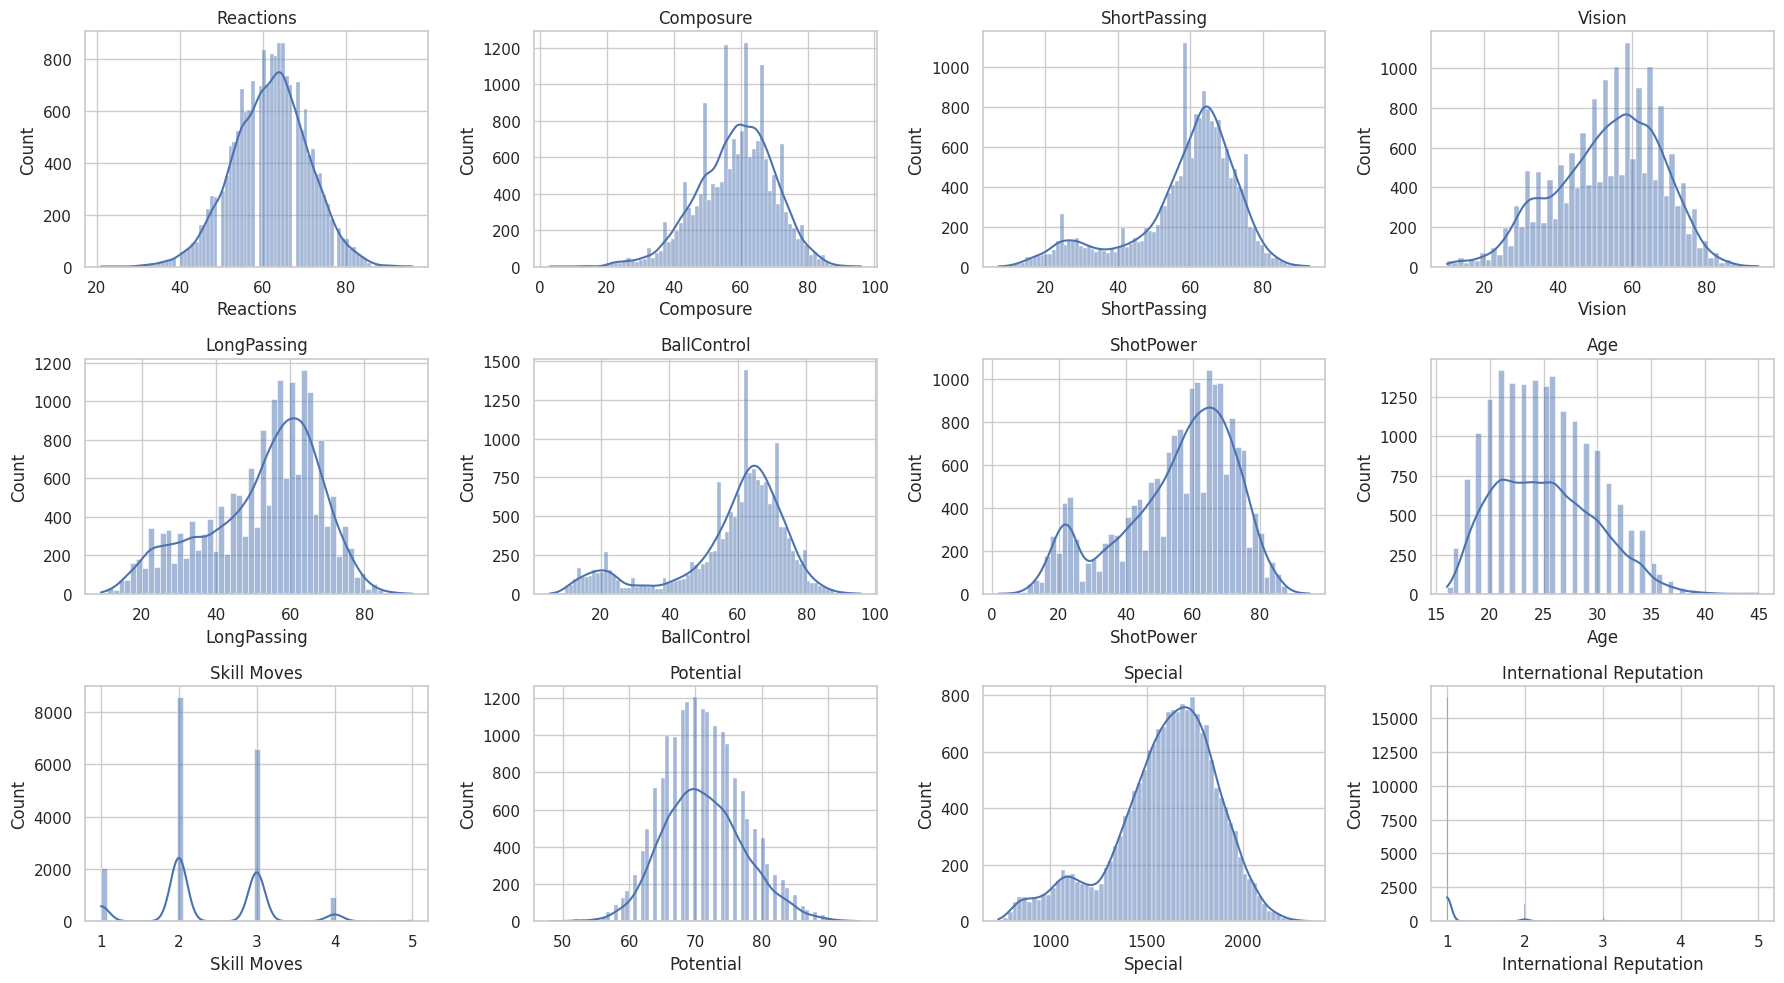

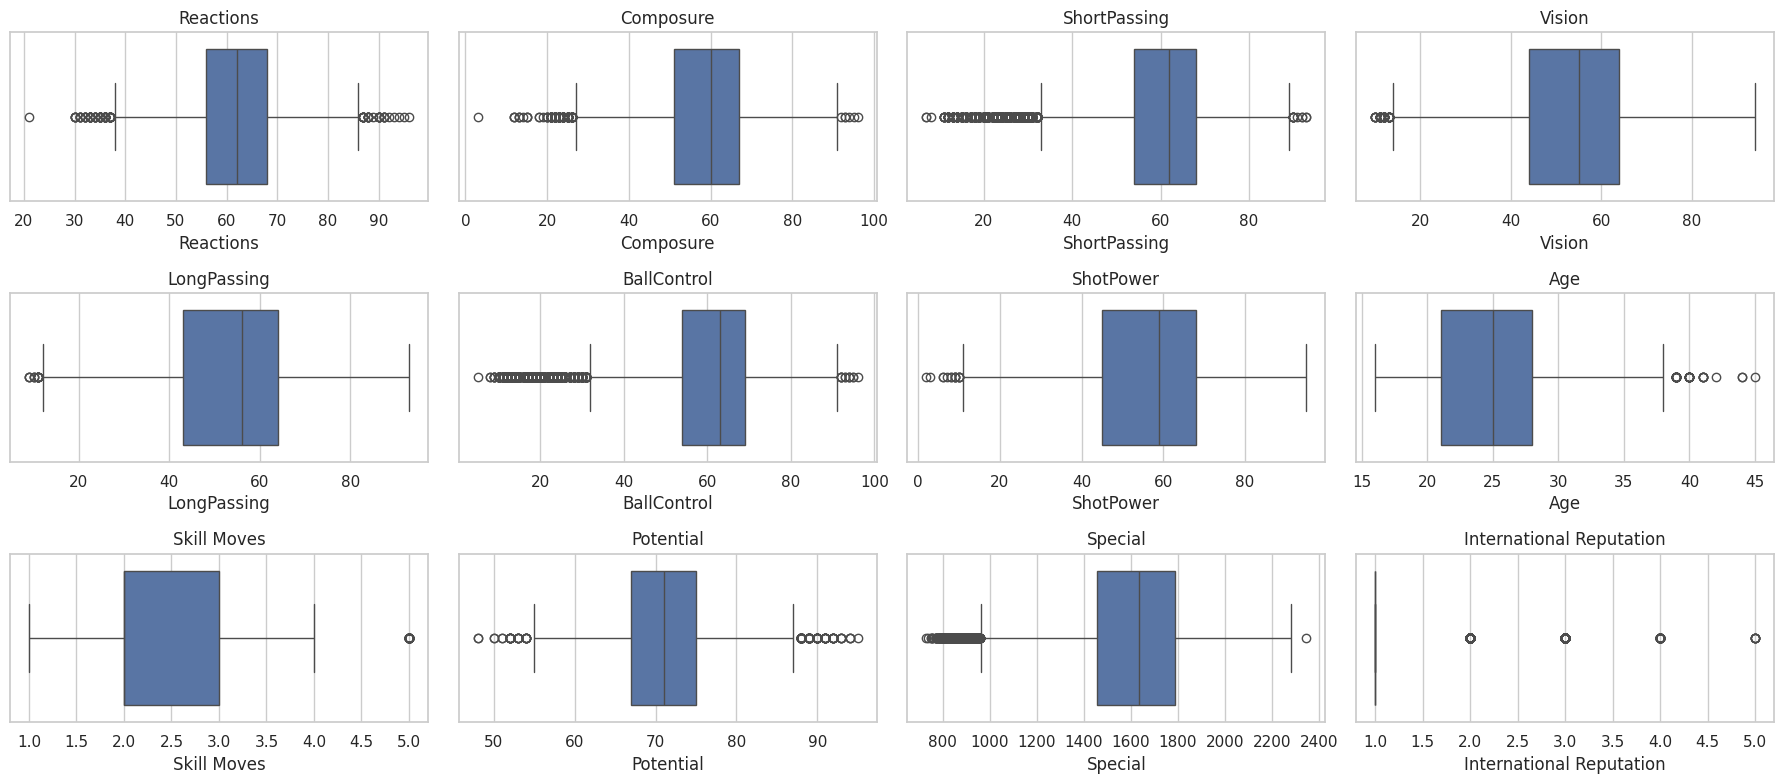

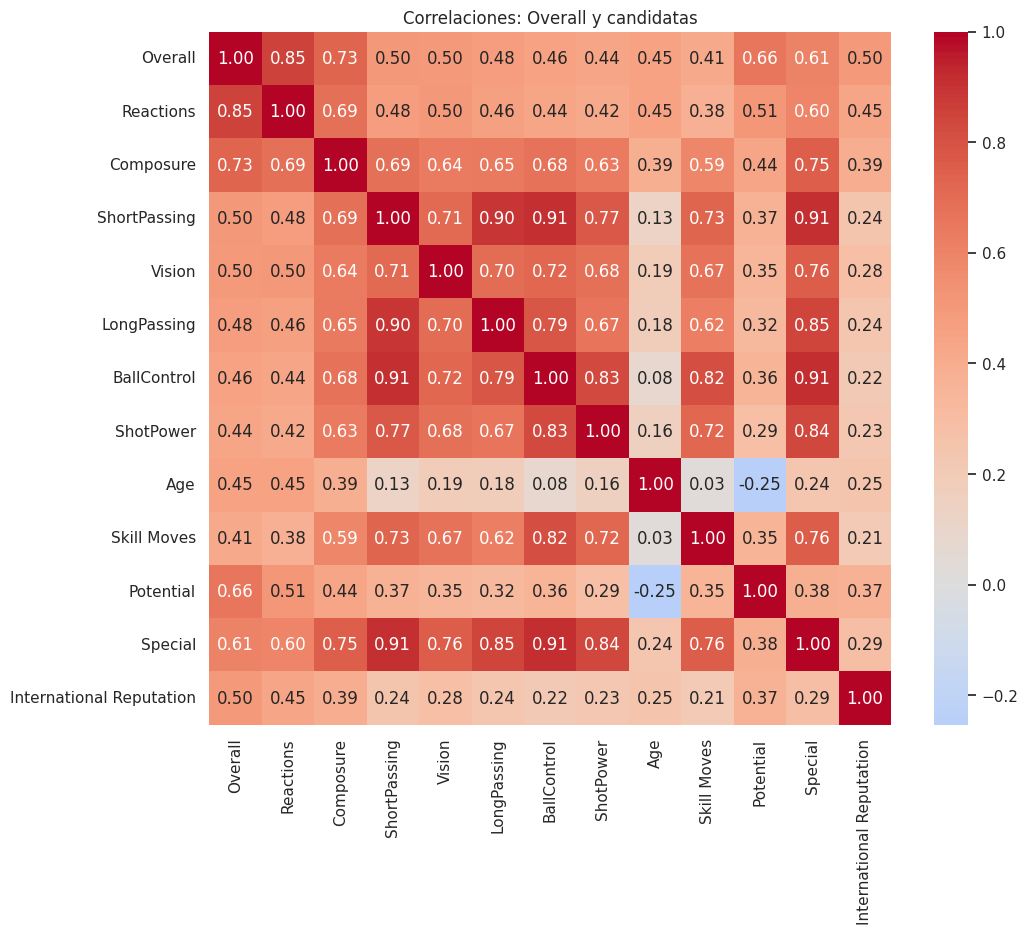

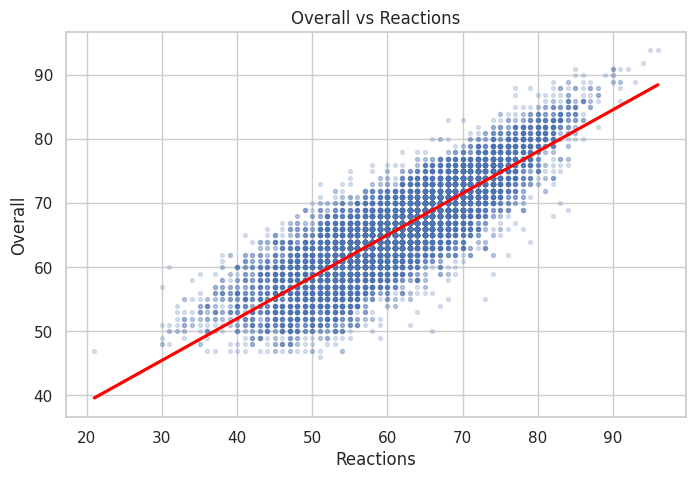

In [15]:
candidatas = ["Reactions", "Composure", "ShortPassing", "Vision", "LongPassing",
              "BallControl", "ShotPower", "Age", "Skill Moves",
              "Potential", "Special", "International Reputation"]

# Histogramas
fig, ejes = plt.subplots(3, 4, figsize=(18, 10))
for ax, v in zip(ejes.ravel(), candidatas):
    sns.histplot(df_f[v].dropna(), kde=True, ax=ax)
    ax.set_title(v)
plt.tight_layout()
plt.show()

# Box-plots
fig, ejes = plt.subplots(3, 4, figsize=(18, 8))
for ax, v in zip(ejes.ravel(), candidatas):
    sns.boxplot(x=df_f[v], ax=ax)
    ax.set_title(v)
plt.tight_layout()
plt.show()

# Correlaciones entre candidatas y Overall
plt.figure(figsize=(11, 9))
sns.heatmap(df_f[["Overall"] + candidatas].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlaciones: Overall y candidatas")
plt.show()

# Regresión de Overall con su predictor más correlacionado
plt.figure(figsize=(8, 5))
sns.regplot(data=df_f, x="Reactions", y="Overall",
            scatter_kws={"alpha": 0.2, "s": 8}, line_kws={"color": "red"})
plt.title("Overall vs Reactions")
plt.show()

VIF CON LongPassing


,variable,VIF
2,ShortPassing,11.78
5,BallControl,10.06
4,LongPassing,5.61
6,ShotPower,3.52
8,Skill Moves,3.33
1,Composure,3.19
3,Vision,2.70
0,Reactions,2.24
7,Age,1.42
9,International Reputation,1.28


VIF SIN LongPassing (predictores finales)


,variable,VIF
4,BallControl,9.94
2,ShortPassing,6.50
5,ShotPower,3.50
7,Skill Moves,3.31
1,Composure,3.18
3,Vision,2.56
0,Reactions,2.23
6,Age,1.41
8,International Reputation,1.28


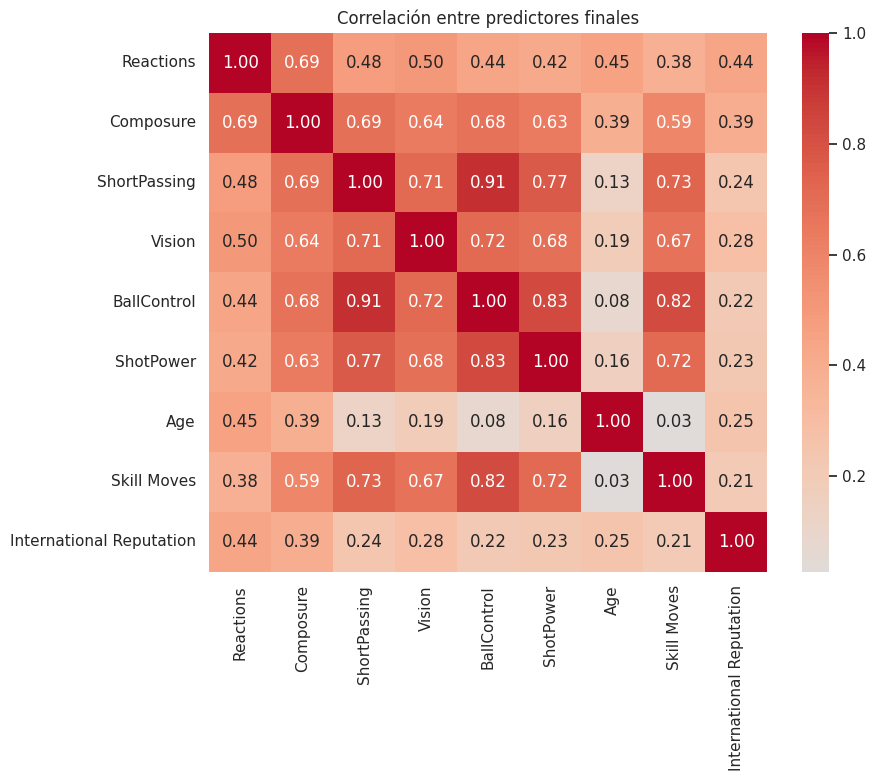

In [16]:
predictores_iniciales = ["Reactions", "Composure", "ShortPassing", "Vision",
                         "LongPassing", "BallControl", "ShotPower", "Age",
                         "Skill Moves", "International Reputation"]
predictores_finales = [p for p in predictores_iniciales if p != "LongPassing"]

# Mismas filas para ambas comparaciones
df_vif = df_f[predictores_iniciales].dropna()

def tabla_vif(datos, cols):
    X = sm.add_constant(datos[cols])
    vif = pd.DataFrame({
        "variable": cols,
        "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]
    })
    return vif.sort_values("VIF", ascending=False).round(2)

print("VIF CON LongPassing")
display(tabla_vif(df_vif, predictores_iniciales))

print("VIF SIN LongPassing (predictores finales)")
display(tabla_vif(df_vif, predictores_finales))

# Matriz de correlación de los predictores finales
plt.figure(figsize=(9, 7))
sns.heatmap(df_vif[predictores_finales].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlación entre predictores finales")
plt.show()

Predictores ( 8 ): ['Reactions', 'Composure', 'ShortPassing', 'Vision', 'ShotPower', 'Age', 'Skill Moves', 'International Reputation']

VIF SIN LongPassing NI BallControl


,variable,VIF
2,ShortPassing,3.55
1,Composure,3.15
4,ShotPower,3.03
6,Skill Moves,2.74
3,Vision,2.55
0,Reactions,2.23
5,Age,1.40
7,International Reputation,1.28


,10 candidatas,sin LongPassing,sin LongPassing ni BallControl
variable,,,
ShortPassing,11.78,6.50,3.55
BallControl,10.06,9.94,NaN
LongPassing,5.61,NaN,NaN
ShotPower,3.52,3.50,3.03
Skill Moves,3.33,3.31,2.74
Composure,3.19,3.18,3.15
Vision,2.70,2.56,2.55
Reactions,2.24,2.23,2.23
Age,1.42,1.41,1.40


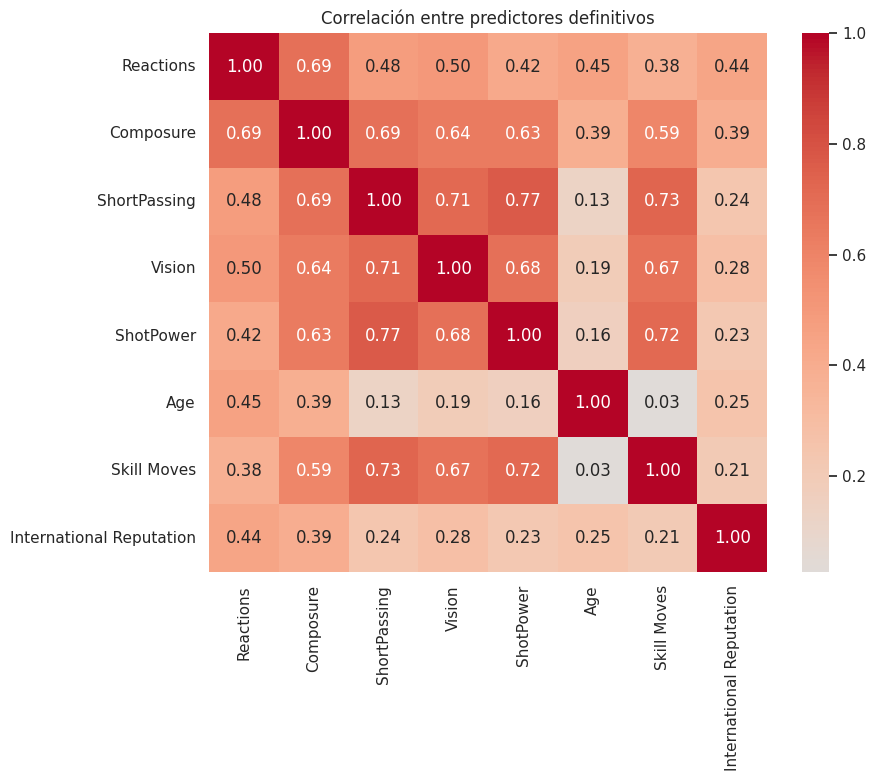

In [17]:
predictores_v3 = [p for p in predictores_finales if p != "BallControl"]
print("Predictores (", len(predictores_v3), "):", predictores_v3)

# Mismas filas que en las comparaciones anteriores
df_vif3 = df_f[predictores_iniciales].dropna()

print("\nVIF SIN LongPassing NI BallControl")
display(tabla_vif(df_vif3, predictores_v3))

# Resumen de las tres etapas para tu informe
etapas = {
    "10 candidatas": tabla_vif(df_vif3, predictores_iniciales).set_index("variable")["VIF"],
    "sin LongPassing": tabla_vif(df_vif3, predictores_finales).set_index("variable")["VIF"],
    "sin LongPassing ni BallControl": tabla_vif(df_vif3, predictores_v3).set_index("variable")["VIF"],
}
display(pd.DataFrame(etapas).round(2).sort_values("10 candidatas", ascending=False))

# Matriz de correlación de los predictores definitivos
plt.figure(figsize=(9, 7))
sns.heatmap(df_vif3[predictores_v3].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlación entre predictores definitivos")
plt.show()

In [18]:
# Verificar la hipótesis de los porteros
bajos = df_f[df_f["ShortPassing"] < 30]
print(bajos["Position"].value_counts().head(8))
print("Proporción de GK entre los de ShortPassing < 30:", round((bajos["Position"] == "GK").mean(), 3))

# Verificar que Special es un agregado de atributos
atributos = df_f.loc[:, "Crossing":"GKReflexes"]
print("Corr. Special vs suma de atributos:", round(df_f["Special"].corr(atributos.sum(axis=1)), 4))

Position
GK     1360
CB       35
LB       10
RB        5
RCB       2
RWB       1
Name: count, dtype: int64
Proporción de GK entre los de ShortPassing < 30: 0.961
Corr. Special vs suma de atributos: 0.9585


1. Variable objetivo (Overall). Cuenta con 18.206 registros válidos (se eliminó 1 sin valor). Su distribución es casi simétrica y en forma de campana (media 66,24, mediana 66, desviación estándar 6,9). Los valores atípicos en ambos extremos (hasta 94 en la zona superior) se conservaron, ya que representan valoraciones reales de jugadores de élite y no errores de registro.

2. Relaciones, distribuciones y heterogeneidad. A partir del gráfico de correlaciones con Overall elegí 10 candidatas: Reactions, Composure, ShortPassing, Vision, LongPassing, BallControl, ShotPower, Age, Skill Moves e International Reputation.

Reactions (0,85) es el predictor más correlacionado y muestra una relación lineal positiva clara, aunque con dispersión considerable alrededor de la recta. Le sigue Composure (0,73). Ambas tienen distribuciones simétricas, con atípicos en los dos lados.
Age es asimétrica hacia la derecha (la mayoría de los jugadores tiene entre 20 y 28 años). Skill Moves es discreta (valores de 1 a 5, concentrada en 2 y 3) e International Reputation se concentra casi por completo en el valor 1.
Las variables técnicas (ShortPassing, LongPassing, BallControl y ShotPower) muestran asimetría hacia la izquierda y una segunda acumulación de valores bajos (20-25), con muchos atípicos inferiores. Comprobé que esta acumulación corresponde mayoritariamente a porteros: el 96,1% de los jugadores con ShortPassing < 30 son GK (1.360 casos; el resto son unos pocos defensas). Esto indica heterogeneidad: las variables específicas de portero tienen correlación casi nula con Overall en el conjunto global, lo que sugiere que modelar porteros y jugadores de campo con una sola recta podría ocultar errores sistemáticos. Se revisará calculando métricas por posición.

3. Control de data leakage. Para garantizar que los predictores existan antes de conocer el Overall, se descartaron:

Por fuga de datos: Potential (estimación de la misma fuente, calculada junto con Overall), Special (índice agregado: su correlación con la suma de los atributos del jugador es de 0,9585), y Value, Wage y Release Clause (consecuencias directas del nivel del jugador).
Por irrelevancia: Jersey Number, al carecer de relación causal con la habilidad.
Mantenidas: los atributos (Reactions, Composure, etc.) son habilidades individuales que existen antes de la valoración global. Overall se calcula a partir de ellas, relación esperable y no fuga.

4. Multicolinealidad (VIF). Se evaluaron las 10 candidatas. ShortPassing (11,78) y BallControl (10,06) superaban el umbral de 10, y LongPassing (5,61) quedaba en zona de alerta.

Fase 1: se eliminó LongPassing (correlación de 0,90 con ShortPassing), y el VIF de ShortPassing bajó a 6,50, pero BallControl casi no cambió (9,94).
Fase 2: se eliminó también BallControl (correlación de 0,91 con ShortPassing), conservando ShortPassing por su correlación algo mayor con Overall (0,50 frente a 0,46).
Resultado: los 8 predictores restantes tienen VIF entre 1,28 y 3,55, y la correlación más alta entre ellos es 0,77 (ShortPassing con ShotPower). La redundancia quedó controlada.

5. Selección final (8 predictores). Reactions, Composure, ShortPassing, Vision, ShotPower, Age, Skill Moves e International Reputation.

Nota sobre International Reputation: se mantiene como medida observable de reconocimiento externo, con información distinta a la de los atributos técnicos (correlaciones de 0,21 a 0,28 con ellos). Puede ser en parte consecuencia del nivel del jugador, pero no se calcula a partir de Overall. Su limitación es que, al estar la mayoría de la muestra en el valor 1, su coeficiente depende en buena medida del grupo de jugadores de élite.

In [19]:
# Solo filas completas en los predictores y en Overall
df_modelo = df_f[predictores_v3 + ["Overall"]].dropna()
print("Filas usadas:", df_modelo.shape[0], "de", df_f.shape[0])

X = df_modelo[predictores_v3]
y = df_modelo["Overall"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

modelo = LinearRegression().fit(X_train, y_train)

def metricas_conjunto(y_real, y_pred):
    return {
        "R²": r2_score(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
    }

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

tabla_metricas = pd.DataFrame({
    "Entrenamiento": metricas_conjunto(y_train, pred_train),
    "Prueba": metricas_conjunto(y_test, pred_test),
}).T
display(tabla_metricas.round(4))

# Coeficientes
print("Intercepto:", round(modelo.intercept_, 4))
tabla_coef = pd.DataFrame({
    "variable": predictores_v3,
    "coeficiente": modelo.coef_
}).sort_values("coeficiente", ascending=False)
display(tabla_coef.round(4))

Filas usadas: 18157 de 18206
Entrenamiento: (14525, 8) | Prueba: (3632, 8)


,R²,MAE,RMSE
Entrenamiento,0.7784,2.5600,3.2603
Prueba,0.7718,2.5661,3.2728


Intercepto: 24.301


,variable,coeficiente
7,International Reputation,2.1337
0,Reactions,0.4668
6,Skill Moves,0.3742
1,Composure,0.1419
5,Age,0.0862
2,ShortPassing,0.0104
3,Vision,-0.0117
4,ShotPower,-0.0120


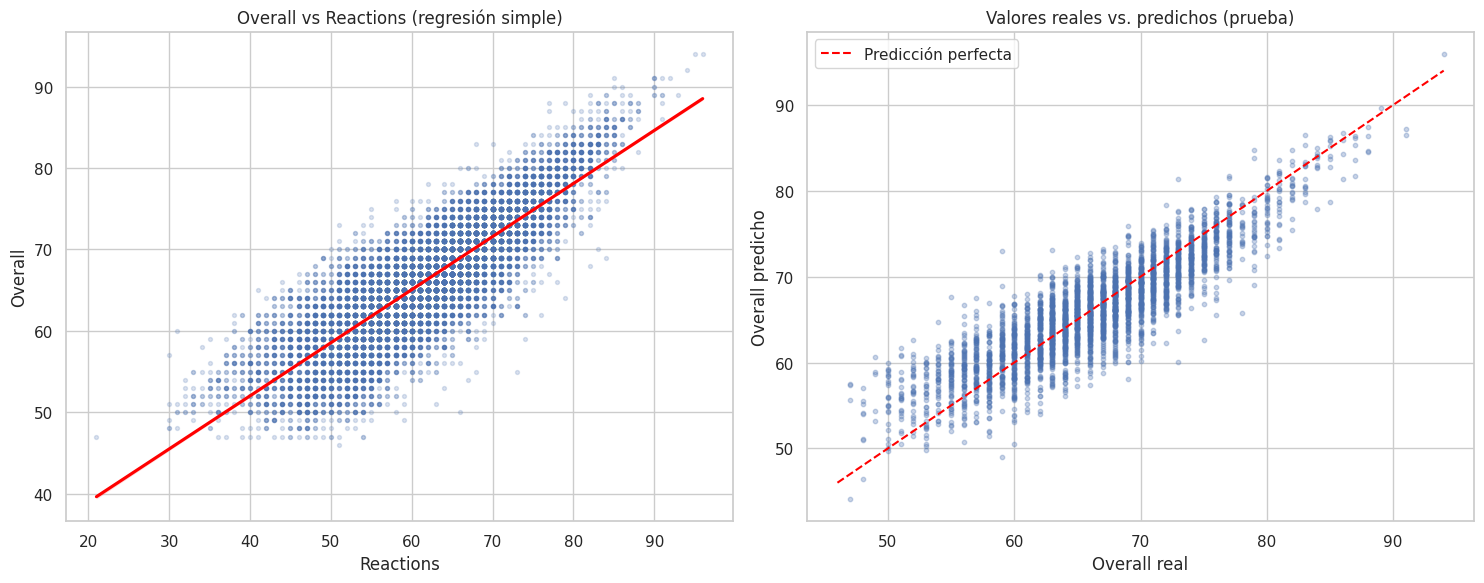

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))

# 1) Regresión del predictor más correlacionado (Reactions) con su línea de regresión
sns.regplot(data=df_modelo, x="Reactions", y="Overall", ax=ejes[0],
            scatter_kws={"alpha": 0.2, "s": 8}, line_kws={"color": "red"})
ejes[0].set_title("Overall vs Reactions (regresión simple)")

# 2) Valores reales vs. predichos (conjunto de prueba)
ejes[1].scatter(y_test, pred_test, alpha=0.3, s=10)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, color="red", linestyle="--", label="Predicción perfecta")
ejes[1].set_xlabel("Overall real")
ejes[1].set_ylabel("Overall predicho")
ejes[1].set_title("Valores reales vs. predichos (prueba)")
ejes[1].legend()

plt.tight_layout()
plt.show()


1. Variable Objetivo (Overall)
Cuenta con 18.206 registros válidos. Su distribución es casi simétrica y en forma de campana (media 66,24, mediana 66, DE 6,9). Los valores atípicos en ambos extremos (llegando hasta 94 en la zona superior) se conservaron, ya que representan valoraciones reales de jugadores de élite y no errores de registro.

2. Relaciones, Distribuciones y HeterogeneidadReactions (0,85) es el predictor con mayor correlación, mostrando una clara relación lineal positiva con el Overall, aunque con dispersión considerable. Le sigue Composure (0,73); ambas presentan distribuciones simétricas.

Por otro lado, las variables técnicas (como ShortPassing, LongPassing, BallControl y ShotPower) muestran asimetría hacia la izquierda con una segunda acumulación de valores bajos (20-25). Es altamente probable que esta acumulación corresponda a los porteros, cuyas habilidades técnicas de campo son mínimas. Esto levanta una señal de heterogeneidad: las variables específicas de portero tienen correlación casi nula en el conjunto global, lo que sugiere que modelar porteros y jugadores de campo en una sola recta podría ocultar errores sistemáticos. Se revisará calculando métricas por posición.

3. Control de Data Leakage y Relevancia
Para evitar fugas de información y garantizar que los predictores sean previos al cálculo del Overall, se descartaron:

Por fuga de datos (Leakage): Potential, Special, Value, Wage y Release Clause. Son derivaciones, índices agregados o consecuencias directas del nivel del jugador.

Por irrelevancia: Jersey Number, al carecer de relación causal con la habilidad.

4. Análisis y Tratamiento de Multicolinealidad (VIF)
Se evaluaron 10 candidatas iniciales. El análisis de Factor de Inflación de Varianza (VIF) detectó un riesgo crítico de redundancia:

Fase 1: ShortPassing (11,78) y BallControl (10,06) superaban ampliamente el umbral aceptable, con LongPassing (5,61) en zona de riesgo.

Fase 2: Se eliminó primero LongPassing (correlación de 0,90 con pases cortos), lo que redujo el VIF de ShortPassing a 6,50, pero dejó a BallControl casi intacto (9,94).

Fase 3: Ante esto, se eliminó también BallControl, conservando únicamente ShortPassing por tener una correlación ligeramente mayor con la variable objetivo (0,50 vs 0,46).

Resultado: Los predictores restantes alcanzaron coeficientes VIF estables (todos por debajo de 3,6) y correlaciones cruzadas máximas de 0,77.

5. Selección Final de Variables (8 predictores)
El modelo predictivo utilizará: Reactions, Composure, ShortPassing, Vision, ShotPower, Age, Skill Moves e International Reputation.

Nota sobre International Reputation: Se mantiene como medida observable de reconocimiento externo, aportando información distinta a los atributos técnicos (correlaciones bajas con el resto de predictores). Su principal limitación es que, al estar la mayoría de la muestra concentrada en el valor 1, su coeficiente predictivo dependerá casi exclusivamente del pequeño grupo de jugadores de élite.

Portero vs. Campo


,n,R²,MAE,RMSE,Sesgo (residuo medio)
Campo,3209.0,0.784,2.473,3.155,-0.159
Portero,420.0,0.671,3.283,4.064,1.764


Por línea


,n,R²,MAE,RMSE,Sesgo (residuo medio)
Defensa,1160.0,0.778,2.329,2.973,0.279
Delantero,667.0,0.833,2.344,2.996,-0.162
Mediocampista,1382.0,0.762,2.656,3.372,-0.526
Portero,420.0,0.671,3.283,4.064,1.764


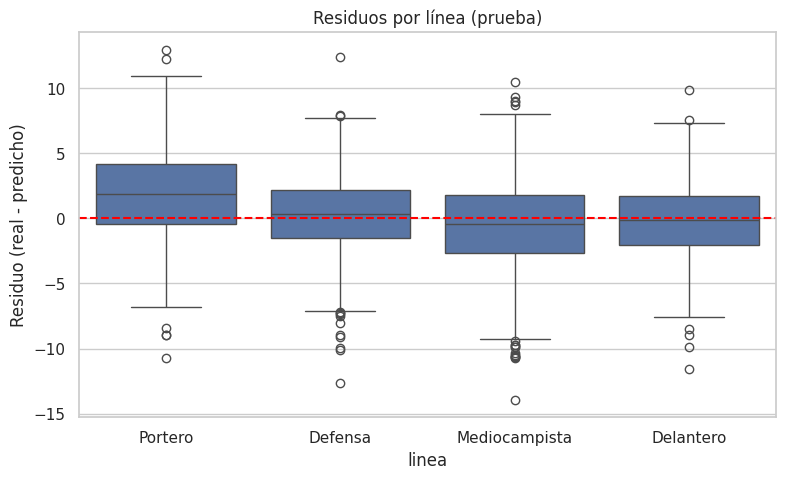

In [21]:
# Posición de cada jugador del conjunto de prueba
pos_test = df_f.loc[X_test.index, "Position"]

def linea(pos):
    if pd.isna(pos):
        return np.nan
    if pos == "GK":
        return "Portero"
    if pos in ["CB", "LCB", "RCB", "LB", "RB", "LWB", "RWB"]:
        return "Defensa"
    if pos in ["CDM", "LDM", "RDM", "CM", "LCM", "RCM", "CAM", "LAM", "RAM", "LM", "RM"]:
        return "Mediocampista"
    return "Delantero"  # LW, RW, ST, LS, RS, CF, LF, RF

res = pd.DataFrame({
    "real": y_test,
    "pred": pred_test,
    "linea": pos_test.map(linea),
})
res["grupo"] = np.where(res["linea"] == "Portero", "Portero", "Campo")
res.loc[res["linea"].isna(), "grupo"] = np.nan
res["residuo"] = res["real"] - res["pred"]

def tabla_por_grupo(col):
    filas = {}
    for g, d in res.dropna(subset=[col]).groupby(col):
        filas[g] = {
            "n": len(d),
            "R²": r2_score(d["real"], d["pred"]),
            "MAE": mean_absolute_error(d["real"], d["pred"]),
            "RMSE": np.sqrt(mean_squared_error(d["real"], d["pred"])),
            "Sesgo (residuo medio)": d["residuo"].mean(),
        }
    return pd.DataFrame(filas).T

print("Portero vs. Campo")
display(tabla_por_grupo("grupo").round(3))

print("Por línea")
display(tabla_por_grupo("linea").round(3))

# Distribución de residuos por línea
plt.figure(figsize=(9, 5))
sns.boxplot(data=res.dropna(subset=["linea"]), x="linea", y="residuo",
            order=["Portero", "Defensa", "Mediocampista", "Delantero"])
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos por línea (prueba)")
plt.ylabel("Residuo (real - predicho)")
plt.show()

1. Heterogeneidad y segmentación del error

Para evaluar si el error del modelo se distribuye de manera uniforme, se analizó el conjunto de prueba dividiendo a los jugadores por su posición (excluyendo 3 registros sin posición definida). Se calculó el sesgo como el residuo medio (valor real − predicho): un sesgo positivo indica que el modelo subvalora al grupo, y uno negativo, que lo sobrevalora.

Grupo	n	R²	MAE	RMSE	Sesgo

Campo	3.209	0,784	2,473	3,155	-0,159

Portero	420	0,671	3,283	4,064	+1,764

Defensa	1.160	0,778	2,329	2,973	+0,279

Mediocampista	1.382	0,762	2,656	3,372	-0,526

Delantero	667	0,833	2,344	2,996	-0,162

2. Análisis de porteros vs. jugadores de campo

Las métricas muestran que el modelo funciona peor en los porteros. Su MAE (3,28) es un 33% superior al de los jugadores de campo (2,47) y su R² baja a 0,67. Además, presenta un sesgo de +1,76: los residuos de los porteros están desplazados hacia valores positivos, es decir, las predicciones quedan en promedio casi 2 puntos por debajo del valor real. En el gráfico de residuos por línea, la caja de los porteros queda desplazada sobre 0 y es más ancha que las de las otras líneas. Hay que considerar que los porteros son solo 420 en el conjunto de prueba, por lo que sus métricas son menos precisas que las de los grupos grandes.

3. Desempeño entre líneas de campo

Dentro de los jugadores de campo, el rendimiento es bastante homogéneo, y los defensas y delanteros presentan los menores errores absolutos (MAE ≈ 2,33). Los mediocampistas muestran un error ligeramente mayor y un sesgo negativo (-0,53), lo que indica una leve tendencia del modelo a sobrevalorarlos. Aunque los delanteros obtuvieron el R² más alto, el MAE y el RMSE indican que su precisión es similar a la de los defensas, ya que el R² depende de cuánto varía Overall dentro de cada grupo.

4. Conclusión y posible causa

El desempeño global (R² de 0,77) enmascara el sesgo en una minoría de jugadores. Una posible explicación es que los 8 predictores seleccionados son atributos de jugadores de campo (pases, remates, visión) y no incluyen las habilidades específicas del puesto de portero (reflejos, estiradas, posicionamiento). Esto muestra que una sola ecuación no describe igual de bien a todos los perfiles de la muestra. Una mejora posible, aunque fuera del alcance de este laboratorio, sería ajustar un modelo independiente para los porteros.

In [22]:
ruta_pel = kagglehub.dataset_download("arjunsinghgangwar/top-250-movies-on-imdb-in-2026")
for raiz, _, archivos in os.walk(ruta_pel):
    for a in archivos:
        print(os.path.join(raiz, a))

100%|██████████| 78.5k/78.5k [00:00<00:00, 21.5MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/arjunsinghgangwar/top-250-movies-on-imdb-in-2026/versions/2/ToP 250 movies on imdb in 2026.csv


In [26]:
import glob

ruta_csv = glob.glob(os.path.join(ruta_pel, "**", "*.csv"), recursive=True)[0]
print("Archivo:", ruta_csv)

try:
    df_pel = pd.read_csv(ruta_csv)
except UnicodeDecodeError:
    df_pel = pd.read_csv(ruta_csv, encoding="cp1252")

print(df_pel.shape)
df_pel.info()
display(df_pel.head())
display(df_pel.describe().T)

Archivo: /root/.cache/kagglehub/datasets/arjunsinghgangwar/top-250-movies-on-imdb-in-2026/versions/2/ToP 250 movies on imdb in 2026.csv
(250, 27)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   250 non-null    object 
 1   url                  250 non-null    object 
 2   primaryTitle         250 non-null    object 
 3   originalTitle        250 non-null    object 
 4   type                 250 non-null    object 
 5   description          250 non-null    object 
 6   primaryImage         250 non-null    object 
 7   thumbnails           250 non-null    object 
 8   trailer              243 non-null    object 
 9   contentRating        244 non-null    object 
 10  startYear            250 non-null    int64  
 11  endYear              0 non-null      float64
 12  releaseDate          249 non-null    object 

,id,url,primaryTitle,originalTitle,type,description,primaryImage,thumbnails,trailer,contentRating,...,filmingLocations,productionCompanies,budget,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,https://www.imdb.com/title/tt0111161/,The Shawshank Redemption,The Shawshank Redemption,movie,After a banker is sentenced to life in Shawsha...,https://m.media-amazon.com/images/M/MV5BMDAyY2...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=xyXX8LXiNJ4,R,...,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,2.942491e+07,['Drama'],False,142,9.3,3219026,82.0
1,tt0068646,https://www.imdb.com/title/tt0068646/,The Godfather,The Godfather,movie,The aging patriarch of an organized crime dyna...,https://m.media-amazon.com/images/M/MV5BNGEwYj...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=8V2k2YQEQJ4,R,...,"[""Forza d'Agrò, Messina, Sicily, Italy""]","[{'id': 'co0023400', 'name': 'Paramount Pictur...",6000000.0,2.509334e+08,"['Crime', 'Drama']",False,175,9.2,2244201,100.0
2,tt0468569,https://www.imdb.com/title/tt0468569/,The Dark Knight,The Dark Knight,movie,When a menace known as the Joker wreaks havoc ...,https://m.media-amazon.com/images/M/MV5BMTMxNT...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=kmJLuwP3MbY,PG-13,...,"['Chicago, Illinois, USA']","[{'id': 'co0002663', 'name': 'Warner Bros.'}, ...",185000000.0,1.008480e+09,"['Crime', 'Thriller']",False,152,9.1,3204629,85.0
3,tt0071562,https://www.imdb.com/title/tt0071562/,The Godfather Part II,The Godfather Part II,movie,The early life and career of Vito Corleone in ...,https://m.media-amazon.com/images/M/MV5BMDIxMz...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=9O1Iy9od7-A,R,...,"['Kaiser Estate - 4000 W Lake Blvd, Homewood, ...","[{'id': 'co0023400', 'name': 'Paramount Pictur...",13000000.0,4.820954e+07,"['Crime', 'Drama']",False,202,9.0,1505420,90.0
4,tt0167260,https://www.imdb.com/title/tt0167260/,The Lord of the Rings: The Return of the King,The Lord of the Rings: The Return of the King,movie,Gandalf and Aragorn lead the World of Men agai...,https://m.media-amazon.com/images/M/MV5BMTZkMj...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=zckJCxYxn1g,PG-13,...,"['Hinuera Valley, Matamata, Waikato, New Zeala...","[{'id': 'co0046718', 'name': 'New Line Cinema'...",94000000.0,1.149454e+09,"['Adventure', 'Drama', 'Fantasy']",False,201,9.0,2181632,94.0


,count,mean,std,min,25%,50%,75%,max
startYear,250.0,1.989448e+03,2.555739e+01,1921.0,1973.25,1996.5,2.009000e+03,2.026000e+03
endYear,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget,226.0,1.809864e+08,1.210412e+09,133000.0,3300000.00,18000000.0,6.300000e+07,1.500000e+10
grossWorldwide,246.0,2.426270e+08,3.789378e+08,2951.0,11491371.00,66120082.5,3.477131e+08,2.799439e+09
runtimeMinutes,250.0,1.317360e+02,3.450374e+01,45.0,109.25,128.5,1.477500e+02,3.740000e+02
averageRating,250.0,8.314400e+00,2.330879e-01,8.0,8.10,8.2,8.400000e+00,9.300000e+00
numVotes,250.0,7.701809e+05,6.315718e+05,25791.0,251428.75,618795.5,1.160524e+06,3.219026e+06
metascore,232.0,8.270259e+01,1.102231e+01,55.0,75.00,85.0,9.100000e+01,1.000000e+02


In [27]:
cols_num = ["averageRating", "numVotes", "runtimeMinutes", "startYear",
            "metascore", "grossWorldwide", "budget"]
print(df_pel[cols_num].isnull().sum())

# ¿Qué películas tienen los presupuestos más altos? (revisar si hay otras monedas)
display(df_pel.nlargest(8, "budget")[["primaryTitle", "startYear", "countriesOfOrigin", "budget", "grossWorldwide"]])

print(df_pel["type"].value_counts())
print(df_pel["contentRating"].value_counts())

averageRating      0
numVotes           0
runtimeMinutes     0
startYear          0
metascore         18
grossWorldwide     4
budget            24
dtype: int64


,primaryTitle,startYear,countriesOfOrigin,budget,grossWorldwide
26,Life Is Beautiful,1997,['IT'],1.500000e+10,2.300990e+08
249,The Handmaiden,2016,['KR'],1.000000e+10,3.796280e+07
82,Princess Mononoke,1997,['JP'],2.400000e+09,3.459853e+07
31,Spirited Away,2001,"['JP', 'US']",2.000000e+09,3.607958e+08
131,Dangal,2016,"['IN', 'US']",7.000000e+08,3.037267e+08
83,3 Idiots,2009,['IN'],5.500000e+08,6.026284e+07
79,Your Name.,2016,['JP'],3.700000e+08,4.056318e+08
73,Avengers: Endgame,2019,['US'],3.560000e+08,2.799439e+09


type
movie    250
Name: count, dtype: int64
contentRating
R            103
PG            37
PG-13         36
Not Rated     22
Approved      19
G             18
Passed         6
Unrated        1
NC-17          1
TV-MA          1
Name: count, dtype: int64


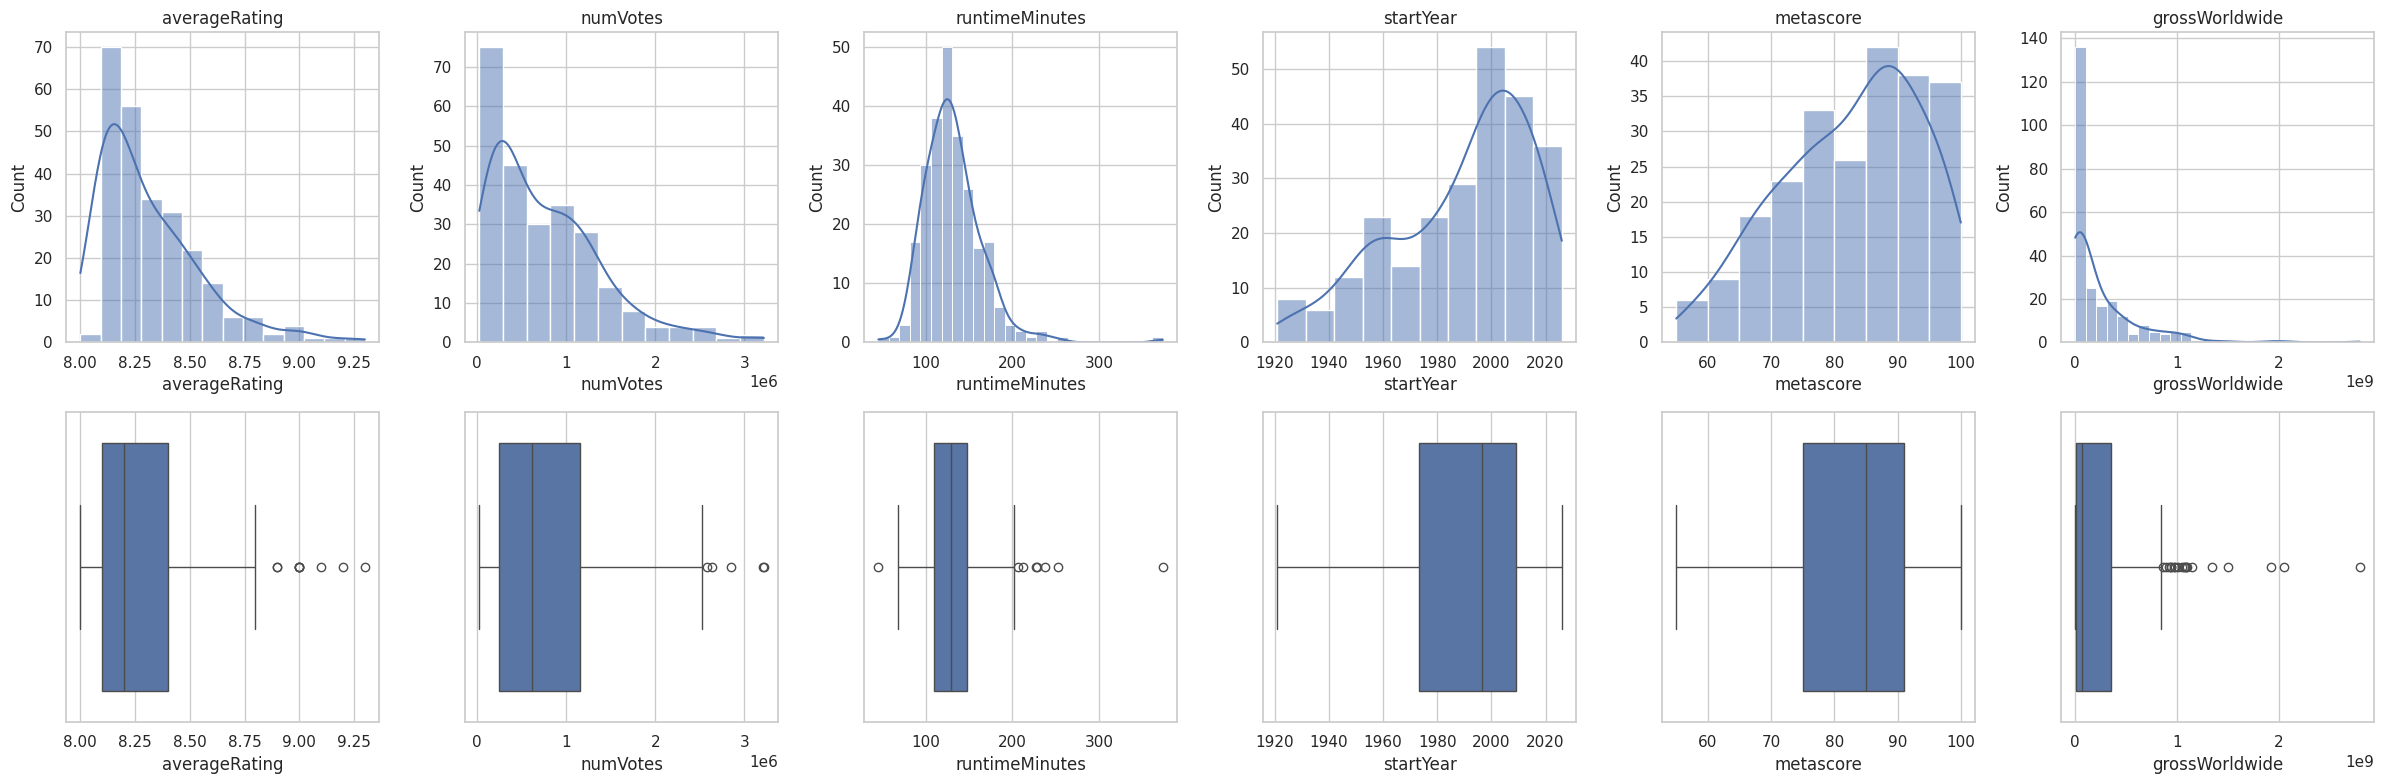

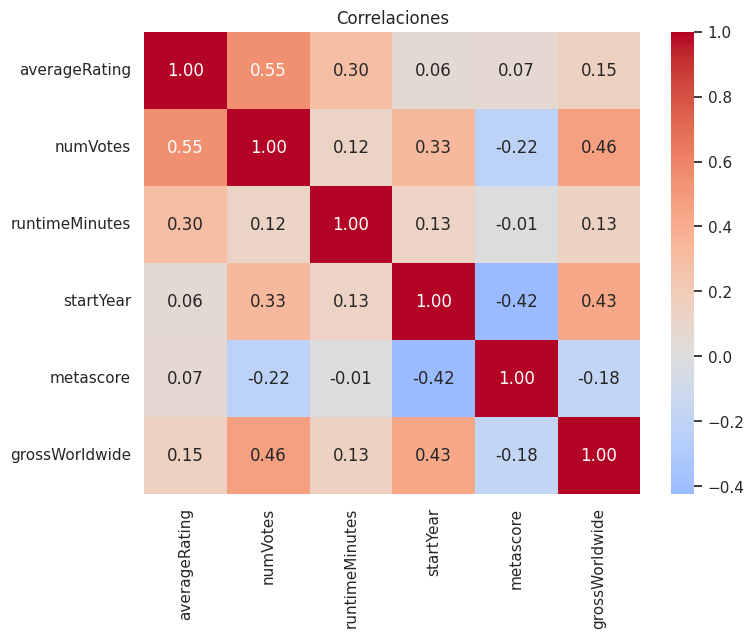

Predictor más correlacionado: numVotes


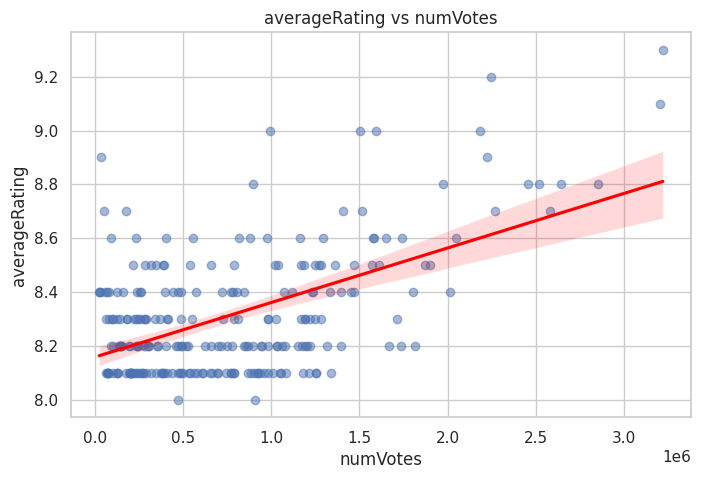

In [28]:
df_p = df_pel.copy()
df_p["decada"] = (df_p["startYear"] // 10) * 10

vars_eda = ["averageRating", "numVotes", "runtimeMinutes", "startYear", "metascore", "grossWorldwide"]

fig, ejes = plt.subplots(2, 6, figsize=(24, 8))
for i, v in enumerate(vars_eda):
    sns.histplot(df_p[v].dropna(), kde=True, ax=ejes[0, i]); ejes[0, i].set_title(v)
    sns.boxplot(x=df_p[v], ax=ejes[1, i])
plt.tight_layout()
plt.show()

corr = df_p[vars_eda].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()

# Regresión con el predictor más correlacionado con averageRating
mejor = corr["averageRating"].drop("averageRating").abs().idxmax()
print("Predictor más correlacionado:", mejor)
plt.figure(figsize=(8, 5))
sns.regplot(data=df_p, x=mejor, y="averageRating",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title(f"averageRating vs {mejor}")
plt.show()

In [29]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def tabla_vif(datos, cols):
    X = sm.add_constant(datos[cols])
    vif = pd.DataFrame({
        "variable": cols,
        "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]
    })
    return vif.sort_values("VIF", ascending=False).round(2)

candidatas = ["numVotes", "runtimeMinutes", "startYear", "metascore", "grossWorldwide"]
df_m = df_p[candidatas + ["averageRating", "decada"]].dropna()
print("Filas usadas:", len(df_m), "de", len(df_p))
display(tabla_vif(df_m, candidatas))

Filas usadas: 231 de 250


,variable,VIF
2,startYear,1.49
4,grossWorldwide,1.43
0,numVotes,1.31
3,metascore,1.23
1,runtimeMinutes,1.02


Filas usadas: 246 de 250
Entrenamiento: (196, 4) | Prueba: (50, 4)


,R²,MAE,RMSE
Entrenamiento,0.3851,0.1437,0.1815
Prueba,0.4532,0.1502,0.1785


Intercepto: 10.3145


,variable,coeficiente
0,numVotes,2.286250e-07
1,runtimeMinutes,1.446596e-03
2,startYear,-1.182912e-03
3,grossWorldwide,-6.642247e-11


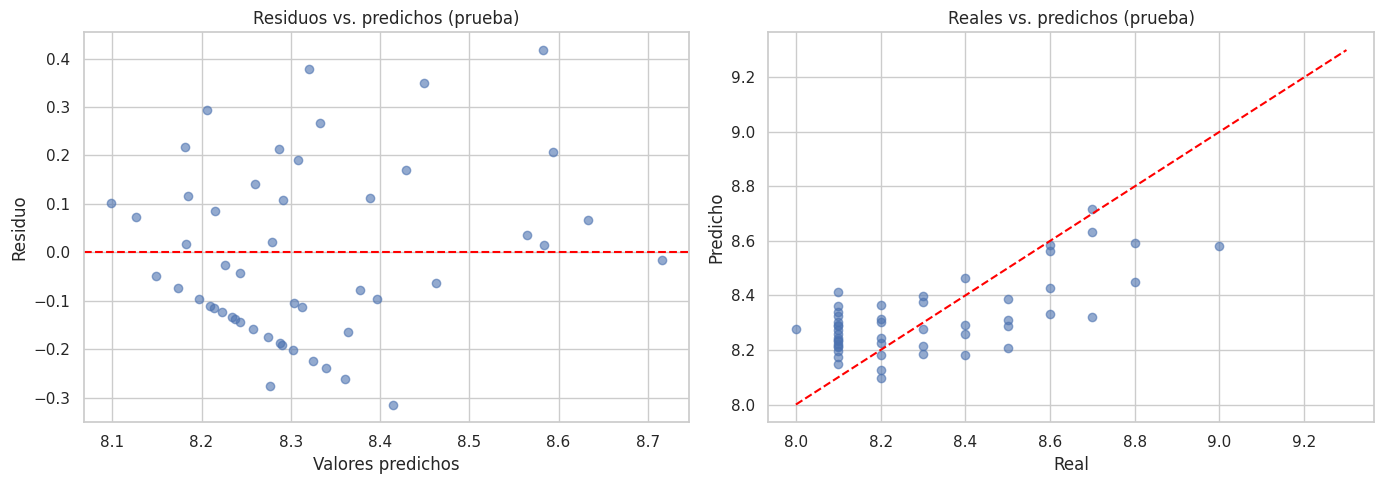

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

predictores = ["numVotes", "runtimeMinutes", "startYear", "grossWorldwide"]  # <- ajusta

df_mod = df_p[predictores + ["averageRating", "decada"]].dropna()
print("Filas usadas:", len(df_mod), "de", len(df_p))

X = df_mod[predictores]
y = df_mod["averageRating"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

modelo = LinearRegression().fit(X_train, y_train)
pred_train, pred_test = modelo.predict(X_train), modelo.predict(X_test)

def met(yr, yp):
    return {"R²": r2_score(yr, yp), "MAE": mean_absolute_error(yr, yp),
            "RMSE": np.sqrt(mean_squared_error(yr, yp))}

display(pd.DataFrame({"Entrenamiento": met(y_train, pred_train),
                      "Prueba": met(y_test, pred_test)}).T.round(4))

print("Intercepto:", round(modelo.intercept_, 4))
display(pd.DataFrame({"variable": predictores, "coeficiente": modelo.coef_}))

residuos = y_test - pred_test
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].scatter(pred_test, residuos, alpha=0.6)
ejes[0].axhline(0, color="red", linestyle="--")
ejes[0].set(title="Residuos vs. predichos (prueba)", xlabel="Valores predichos", ylabel="Residuo")
ejes[1].scatter(y_test, pred_test, alpha=0.6)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, color="red", linestyle="--")
ejes[1].set(title="Reales vs. predichos (prueba)", xlabel="Real", ylabel="Predicho")
plt.tight_layout()
plt.show()

EDA
1. Análisis de la Variable Objetivo (averageRating)
El modelo busca predecir una muestra de 250 películas que oscilan entre 8,0 y 9,3 puntos (media de 8,31; DE de 0,23). La distribución presenta asimetría hacia la derecha con valores atípicos por encima de 8,8. Dado que se trata del Top 250, estamos ante una muestra truncada (solo la élite del cine). Esta concentración en un rango tan estrecho limita severamente la variabilidad de los datos, lo que incrementará la dificultad predictiva del modelo.

2. Limpieza y Exclusión de Variables (No modelables)
Se descartaron los metadatos de texto, enlaces e identificadores únicos. Además, se eliminaron variables estructuralmente inútiles para este análisis:


*   type (valor constante "movie").
*   endYear (100% de valores nulos).
*   budget (mezcla de monedas locales no estandarizadas, lo que invalida su comparación directa).

3. Correlaciones, Fuga de Datos y Selección de Predictores
Se evaluaron los candidatos en función de su correlación y su naturaleza respecto a la variable objetivo:

*    numVotes (0,55): Es el predictor más fuerte. El gráfico de dispersión confirma una tendencia positiva, aunque con alta variabilidad e influencia de casos extremos (películas con más de 3 millones de votos). Limitación a considerar: El Top 250 de IMDb exige un umbral mínimo de votos para ingresar a la lista, lo que introduce un sesgo de selección inherente en esta variable.
*    runtimeMinutes (0,30) y startYear (0,06): Se conservan por ser características estructurales de la obra, previas a la calificación.
*    grossWorldwide (0,15): Se mantiene en el modelo. Si bien la recaudación es posterior al estreno, es una variable independiente de la calificación de los usuarios.
*    metascore (0,07 - Descartada): Se excluyó por tres motivos: su bajísima correlación, el costo de perder 18 registros por datos faltantes, y el riesgo conceptual de data leakage, al ser una valoración paralela (de críticos) muy cercana a la variable objetivo.

4. Análisis de Multicolinealidad y Dataset Final
La prueba de Factor de Inflación de Varianza (VIF) confirmó que no existe redundancia entre las variables. Todos los candidatos obtuvieron valores excelentes (≤ 1,49), siendo el más alto startYear (1,49) y el más bajo runtimeMinutes (1,02).

En conclusión, el modelo final se construirá con 4 predictores (numVotes, runtimeMinutes, startYear y grossWorldwide) aplicados sobre 246 películas (tras excluir 4 observaciones sin datos de recaudación global).

Conjunto de prueba


,n,R²,MAE,RMSE,Sesgo
Antes de 1980,20.0,0.181,0.151,0.175,-0.021
1980-1999,12.0,0.566,0.129,0.171,0.028
2000 o después,18.0,0.433,0.164,0.187,-0.012


Validación cruzada (246 películas)


,n,R²,MAE,RMSE,Sesgo
Antes de 1980,74.0,0.369,0.148,0.184,0.011
1980-1999,65.0,0.619,0.126,0.157,-0.008
2000 o después,107.0,0.149,0.160,0.202,0.001


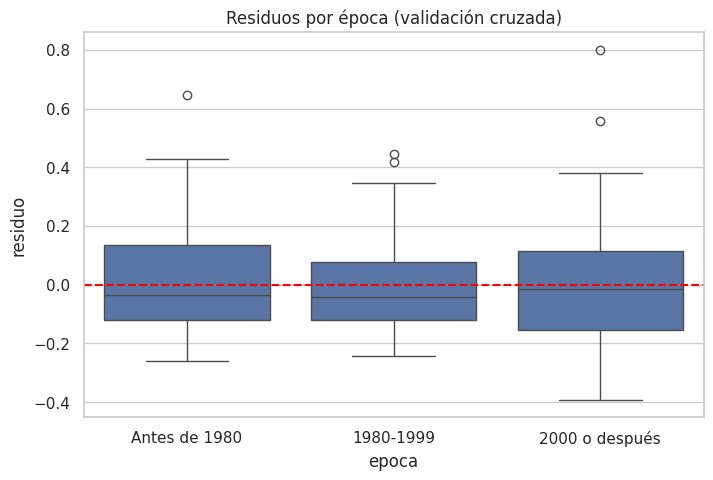

In [31]:
from sklearn.model_selection import cross_val_predict, KFold

def epoca(a):
    if a < 1980: return "Antes de 1980"
    if a < 2000: return "1980-1999"
    return "2000 o después"

orden = ["Antes de 1980", "1980-1999", "2000 o después"]
df_mod = df_mod.copy()
df_mod["epoca"] = df_mod["startYear"].map(epoca)

# (a) Conjunto de prueba
res_test = pd.DataFrame({"real": y_test, "pred": pred_test,
                         "epoca": df_mod.loc[y_test.index, "epoca"]})

# (b) Predicciones fuera de muestra (5 pliegues) sobre las 246 películas
pred_cv = cross_val_predict(LinearRegression(), X, y,
                            cv=KFold(5, shuffle=True, random_state=42))
res_cv = pd.DataFrame({"real": y, "pred": pred_cv, "epoca": df_mod["epoca"]})

def tabla(res):
    filas = {}
    for g, d in res.groupby("epoca"):
        filas[g] = {"n": len(d),
                    "R²": r2_score(d.real, d.pred),
                    "MAE": mean_absolute_error(d.real, d.pred),
                    "RMSE": np.sqrt(mean_squared_error(d.real, d.pred)),
                    "Sesgo": (d.real - d.pred).mean()}
    return pd.DataFrame(filas).T.loc[orden]

print("Conjunto de prueba"); display(tabla(res_test).round(3))
print("Validación cruzada (246 películas)"); display(tabla(res_cv).round(3))

res_cv["residuo"] = res_cv["real"] - res_cv["pred"]
plt.figure(figsize=(8, 5))
sns.boxplot(data=res_cv, x="epoca", y="residuo", order=orden)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos por época (validación cruzada)")
plt.show()

Se segmentó a las películas en tres épocas según startYear (antes de 1980, 1980-1999 y 2000 o después). Como el conjunto de prueba tiene solo 50 películas (entre 12 y 20 por grupo), calculé además las métricas con predicciones fuera de muestra mediante validación cruzada de 5 pliegues sobre las 246 películas, que son más estables, y baso el análisis principalmente en esa tabla.

Época	n R²	MAE	RMSE	Sesgo

Antes de 1980	74	0,369	0,148	0,184	+0,011

1980-1999	65	0,619	0,126	0,157	-0,008

2000 o después	107	0,149	0,160	0,202	+0,001

El sesgo es cercano a 0 en las tres épocas, por lo que el modelo no sobrevalora ni subvalora de forma sistemática a ningún grupo. Sin embargo, la precisión sí difiere: el modelo funciona mejor en las películas de 1980-1999 y peor en las de 2000 en adelante, donde el RMSE (0,202) es cerca de un 29% mayor y el R² baja a 0,149. El box-plot de residuos lo respalda: la caja de 2000 o después es la más ancha y contiene los residuos más extremos. Como el R² depende de cuánto varía la calificación dentro de cada grupo, para comparar me apoyo más en el MAE y el RMSE. La tabla de prueba no permite conclusiones, porque con 12 a 20 películas por grupo sus resultados son inestables y el orden entre épocas incluso cambia.

Preguntas de cierre:

1. Interpretación del Coeficiente (numVotes)
Su impacto es positivo pero modesto (es una asociación, no una relación causal). Por cada millón de votos adicionales, la calificación sube en promedio apenas 0,23 puntos, lo que equivale exactamente a la desviación estándar natural de la muestra.

2. Desempeño y Generalización (Entrenamiento vs. Prueba)
El modelo es estable y no presenta sobreajuste: las métricas de error son casi idénticas en ambos conjuntos (MAE ≈ 0,15; RMSE ≈ 0,18). Aunque el modelo ayuda a predecir (su error equivale a dos tercios de la desviación estándar), deja mucha variabilidad sin explicar. El hecho de que el R² sea mayor en la prueba (0,45 vs 0,38) no indica mayor precisión, sino que es un efecto del tamaño reducido de esa muestra (solo 50 películas).

3. Diagnóstico de Supuestos y Residuos
Se incumple parcialmente el supuesto de aleatoriedad en los residuos. El diagnóstico visual revela que el modelo comprime sus estimaciones en un rango muy estrecho (8,1 a 8,7) y subestima sistemáticamente a las películas con calificaciones más altas, formando patrones diagonales en el error. La causa más probable de esta anomalía es que la variable objetivo es de naturaleza discreta (un decimal) y está artificialmente truncada en 8,0.